# Time Series Analysis

In [129]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [130]:
# Import all 3 datasets
recalls_a = pd.read_csv("../data/csv/recalls_2016_2021.csv")
recalls_b = pd.read_csv("../data/csv/recalls_2022_2025.csv")
recalls_c = pd.read_csv("../data/csv/recalls_2025_april.csv")

In [131]:
# Subset 3 important columns
recalls_a_edit = recalls_a[["year", "date", "product_name"]]
recalls_b_edit = recalls_b[["year", "date", "product_name"]]
recalls_c_edit = recalls_c[["year", "date", "product_name"]]

In [144]:
stacked = pd.concat([recalls_a_edit, recalls_b_edit, recalls_c_edit], ignore_index=True)

In [133]:
stacked.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          169 non-null    int64 
 1   date          169 non-null    object
 2   product_name  169 non-null    object
dtypes: int64(1), object(2)
memory usage: 4.1+ KB


In [134]:
# run formula to format date column
def fix_year_format(d):
    if pd.isna(d):  # skip missing
        return d
    # Match dd/mm/yy
    if re.match(r"\d{2}/\d{2}/\d{2}$", d):
        day, month, year = d.split("/")
        year = "20" + year if int(year) <= 25 else "19" + year  # adjust threshold as needed
        return f"{day}/{month}/{year}"
    return d

In [135]:
# Convert data format: year and date column
stacked["year"] = pd.to_datetime(stacked["year"],format="%Y")
stacked["date"] = stacked["date"].apply(fix_year_format)

In [136]:
# convert data types

## year column
stacked["year"] = stacked["year"].dt.date

## date column
stacked["date"] = pd.to_datetime(stacked["date"],format="%d/%m/%Y")
stacked["date"] = stacked["date"].dt.date

## sort by date column
stacked_clean = stacked.sort_values("date")

Product name cleaning

In [137]:
# Standardize case and remove special characters
stacked_clean["product_name"] = stacked_clean["product_name"].str.title().apply(lambda x: re.sub(r'[^\x00-\x7F]+', ' ', x)).str.strip().str.lower()

In [138]:
def infer_drug_class(product_name):
    product_name = product_name.lower()
    
    # Analgesics / Pain Relief
    if any(x in product_name for x in ["paracetamol", "painil", "curamol", "medimol", "jotonol", "dawasprin", "aspirin", "dolac", "tamedol", "apc", "parol", "paratal", "betamol", "biomol", "blink", "lumidol", "paragen", "totomol"]):
        return "Analgesic"
    
    # Antibiotics
    if any(x in product_name for x in ["amoxicillin", "claxy", "elymox", "labmox", "strox", "kemoxyl", "rocephin", "clindar", "cosatrim", "amoxiclav", "rapiclav", "beeclav", "dawaflox", "mesporin", "trimoxol", "azithrosafe", "erocin", "altacef", "biotrim", "cipcina", "izzithree", "metrosim", "unibrol"]):
        return "Antibiotic"
    
    # Anthelmintics
    if any(x in product_name for x in ["almex", "abz", "tanzol", "alben", "olworm", "zolex"]):
        return "Anthelmintic"
    
    # Antifungals
    if any(x in product_name for x in ["fluconazole", "kenazole", "dazole"]):
        return "Antifungal"
    
    # Antivirals
    if any(x in product_name for x in ["tenofovir", "atazor-r"]):
        return "Antiviral"
    
    # Antipsychotics
    if any(x in product_name for x in ["fluphenazine", "chlorpromazine", "normnil"]):
        return "Antipsychotic"
    
    # Antihypertensives
    if any(x in product_name for x in ["acepril", "losar-denk", "co-losar", "irbesatan", "carvedi-denk", "flamodip", "bisotrol", "medopress", "enril"]):
        return "Antihypertensive"
    
    # Antacids / Gastrointestinal
    if any(x in product_name for x in ["dawapraz", "stopacid", "rabemac", "s-prazo", "alkar-ur", "allucid", "beta gripe", "dto", "festate", "magnocid", "pregsmile"]):
        return "Gastrointestinal"
    
    # Cough Syrups / Expectorants
    if any(x in product_name for x in ["upacof", "triohist", "carbocysten", "benylin", "caryl", "tricohist", "shaltoux", "toramin", "nycodeal"]):
        return "Cough/Expectorant"
    
    # Contraceptives
    if any(x in product_name for x in ["levonogets", "moods", "sure lubricated", "fiesta", "rough rider", "wombit"]):
        return "Contraceptive"
    
    # Anticoagulants
    if any(x in product_name for x in ["clopidogrel", "warfarin"]):
        return "Anticoagulant"
    
    # Laxatives
    if any(x in product_name for x in ["dulcolax"]):
        return "Laxative"
    
    # Antihistamines
    if any(x in product_name for x in ["rinacet"]):
        return "Antihistamine"
    
    # Diuretics
    if any(x in product_name for x in ["frusemide", "lasideal"]):
        return "Diuretic"
    
    # Topical Agents
    if any(x in product_name for x in ["silvadine", "silvamax", "dinac", "umbicare", "diarim", "deep heat", "pharmasal", "zeosorb"]):
        return "Topical Agent"
    
    # Vitamins/Supplements
    if any(x in product_name for x in ["ascorbic acid", "famcal", "mz-cal", "topfoliferum", "methomine s", "neuropower"]):
        return "Vitamin/Supplement"
    
    # Antimalarials
    if any(x in product_name for x in ["lamprene"]):
        return "Antimalarial"
    
    # Neuromuscular Agents
    if any(x in product_name for x in ["atracurium", "atravita"]):
        return "Neuromuscular Agent"
    
    # Bronchodilators
    if any(x in product_name for x in ["asmol", "ventil", "denk-air", "doximar"]):
        return "Bronchodilator"
    
    # Anti-TB
    if any(x in product_name for x in ["tbcide"]):
        return "Anti-TB"
    
    # Local Anesthetics
    if any(x in product_name for x in ["lidocel", "nurabucaine"]):
        return "Local Anesthetic"
    
    # Antidepressants
    if any(x in product_name for x in ["amitrip"]):
        return "Antidepressant"
    
    # Rehydration Salts
    if any(x in product_name for x in ["dts-z", "glucose 5d"]):
        return "Rehydration Salts"
    
    # Hormones
    if any(x in product_name for x in ["oxytocin"]):
        return "Hormone"
    
    # Immunoglobulins
    if any(x in product_name for x in ["rhoclone"]):
        return "Immunoglobulin"
    
    # Medical Device/Suture
    if any(x in product_name for x in ["suture", "vasofix", "microplas", "safil", "novosyne"]):
        return "Medical Device/Suture"
    
    # Antiprotozoals
    if any(x in product_name for x in ["trogyl", "metrowin"]):
        return "Antiprotozoal"
    
    # Antiepileptics
    if any(x in product_name for x in ["biodopa", "dopamac"]):
        return "Antiepileptic"
    
    # Corticosteroids
    if any(x in product_name for x in ["diprofos"]):
        return "Corticosteroid"
    
    # Mouthwashes/Antiseptics
    if any(x in product_name for x in ["biodine", "oralex", "klincord"]):
        return "Mouthwash/Antiseptic"
    
    # Plasma Expanders
    if any(x in product_name for x in ["haemaccel"]):
        return "Plasma Expander"
    
    # Muscle Relaxants
    if any(x in product_name for x in ["sigmaflex"]):
        return "Muscle Relaxant"
    
    # Nasal Decongestants
    if any(x in product_name for x in ["efinox"]):
        return "Nasal Decongestant"
    
    # Antineoplastics
    if any(x in product_name for x in ["flurasted"]):
        return "Antineoplastic"
    
    # Vaccines
    if any(x in product_name for x in ["opvero"]):
        return "Vaccine"
    
    # Unknown/Other (for drugs with unclear classification)
    return "Unknown/Other"

In [139]:
stacked_clean["drug_class"] = stacked_clean["product_name"].apply(infer_drug_class)

In [140]:
counts = stacked.groupby(["date", "product_name"]).size().reset_index(name="count")
pivot = counts.pivot(index="date", columns="product_name", values="count").fillna(0)
print(pivot)

product_name  8-0  Blue twisted silk suture  ABZ tablet  APC Tablets  \
date                                                                   
2013-12-11                              0.0         0.0          0.0   
2015-09-24                              0.0         0.0          0.0   
2016-06-15                              0.0         0.0          0.0   
2017-03-29                              0.0         0.0          0.0   
2017-04-05                              0.0         0.0          0.0   
...                                     ...         ...          ...   
2025-03-11                              0.0         0.0          0.0   
2025-03-19                              0.0         0.0          0.0   
2025-03-21                              0.0         0.0          0.0   
2025-04-03                              0.0         0.0          0.0   
2025-04-24                              0.0         0.0          0.0   

product_name  Acepril 5mg  Alben oral suspension  \
date       

In [141]:
daily_totals = stacked_clean.groupby("date").size().reset_index(name="count")

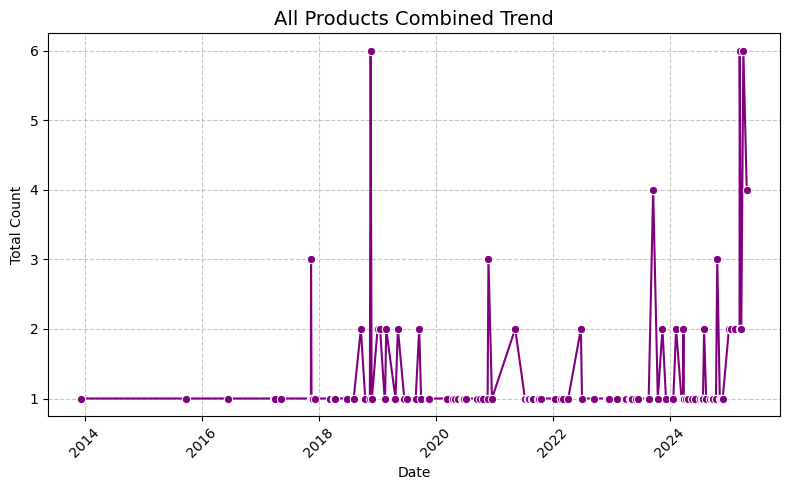

In [142]:
plt.figure(figsize=(8,5))
sns.lineplot(data=daily_totals, x="date", y="count", marker="o", color="purple")
plt.title("All Products Combined Trend", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Total Count")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [143]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(daily_totals["count"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])


ADF Statistic: -1.0641659531232837
p-value: 0.7291485890014328
Critical Values: {'1%': np.float64(-3.4865346059036564), '5%': np.float64(-2.8861509858476264), '10%': np.float64(-2.579896092790057)}


Results show data is non stationary.  
Next steps involve:  
- transforming. Using Differencing.  
- log transform + differencing

In [111]:
# First difference
daily_totals["diff_1"] = daily_totals["count"].diff().dropna()

# Run ADF on differenced data
result_diff = adfuller(daily_totals["diff_1"].dropna())

print("ADF Statistic (1st diff):", result_diff[0])
print("p-value:", result_diff[1])
print("Critical Values:", result_diff[4])

ADF Statistic (1st diff): -11.218095102160172
p-value: 2.0456042294993776e-20
Critical Values: {'1%': np.float64(-3.4865346059036564), '5%': np.float64(-2.8861509858476264), '10%': np.float64(-2.579896092790057)}


The differenced series is now stationary.  
Original data was non-stationary (trending upward).  
After first differencing, it became stationary → ready for time series modeling (e.g., ARMA/ARIMA/SARIMA, forecasting).

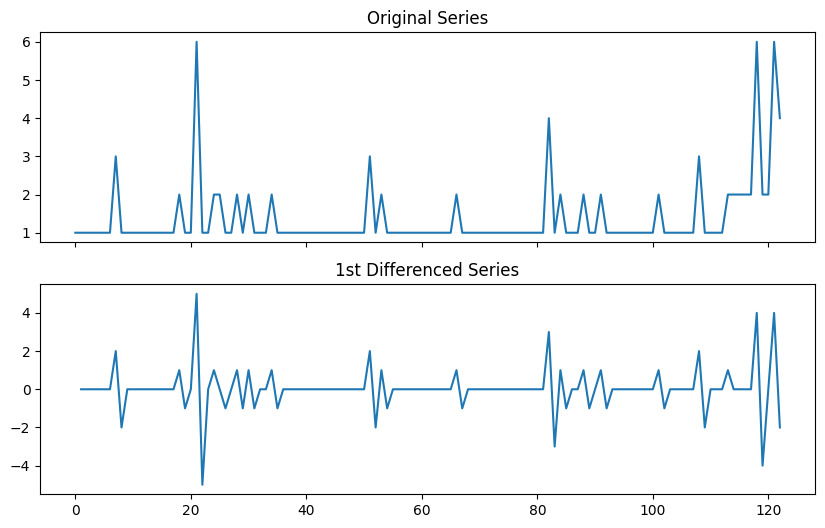

In [112]:
fig, axes = plt.subplots(2, 1, figsize=(10,6), sharex=True)
daily_totals["count"].plot(ax=axes[0], title="Original Series")
daily_totals["diff_1"].plot(ax=axes[1], title="1st Differenced Series")
plt.show()

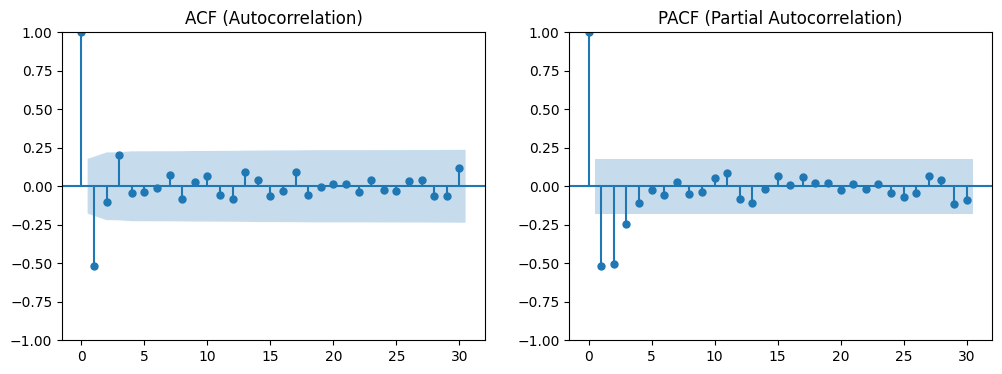

In [113]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(12,4))

plot_acf(daily_totals["diff_1"].dropna(), lags=30, ax=axes[0])
plot_pacf(daily_totals["diff_1"].dropna(), lags=30, ax=axes[1])

axes[0].set_title("ACF (Autocorrelation)")
axes[1].set_title("PACF (Partial Autocorrelation)")
plt.show()

Describe ACF and PACF 

In [114]:
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA(2,1,1)
model = ARIMA(daily_totals["count"], order=(2,1,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  count   No. Observations:                  123
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -151.596
Date:                Thu, 28 Aug 2025   AIC                            311.191
Time:                        19:13:22   BIC                            322.407
Sample:                             0   HQIC                           315.747
                                - 123                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4560      0.128     -3.573      0.000      -0.706      -0.206
ar.L2         -0.3672      0.083     -4.425      0.000      -0.530      -0.205
ma.L1         -0.4599      0.145     -3.170      0.0

In [116]:
import itertools

# Define ranges for p, d, q
p = range(0, 4)   # AR order
d = range(0, 2)   # Differencing
q = range(0, 3)   # MA order

# Generate all (p,d,q) combinations
pdq = list(itertools.product(p, d, q))


In [117]:
results = []

for param in pdq:
    try:
        model = ARIMA(daily_totals["count"], order=param)
        model_fit = model.fit()
        results.append([param, model_fit.aic])
    except:
        continue

# Collect into DataFrame
results_df = pd.DataFrame(results, columns=["order", "AIC"])
results_df = results_df.sort_values(by="AIC")
print(results_df.head(10))  # best 10 models


c:\Users\david.andai\OneDrive - Aga Khan University\Documents\PROJECTS\Project 1-5\ppb_recalls\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\david.andai\OneDrive - Aga Khan University\Documents\PROJECTS\Project 1-5\ppb_recalls\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\david.andai\OneDrive - Aga Khan University\Documents\PROJECTS\Project 1-5\ppb_recalls\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\david.andai\OneDrive - Aga 

        order         AIC
16  (2, 1, 1)  311.191332
21  (3, 1, 0)  311.727124
22  (3, 1, 1)  313.060963
17  (2, 1, 2)  313.113078
23  (3, 1, 2)  314.696125
5   (0, 1, 2)  314.983487
11  (1, 1, 2)  315.828721
19  (3, 0, 1)  316.265137
15  (2, 1, 0)  317.121890
10  (1, 1, 1)  317.348309


In [119]:
best_order = results_df.iloc[0]["order"]
print("Best ARIMA order:", best_order)

best_model = ARIMA(daily_totals["count"], order=best_order)
best_fit = best_model.fit()
print(best_fit.summary())

Best ARIMA order: (2, 1, 1)
                               SARIMAX Results                                
Dep. Variable:                  count   No. Observations:                  123
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -151.596
Date:                Thu, 28 Aug 2025   AIC                            311.191
Time:                        19:29:36   BIC                            322.407
Sample:                             0   HQIC                           315.747
                                - 123                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4560      0.128     -3.573      0.000      -0.706      -0.206
ar.L2         -0.3672      0.083     -4.425      0.000      -0.530      -0.205
ma.L1         -0.4599   

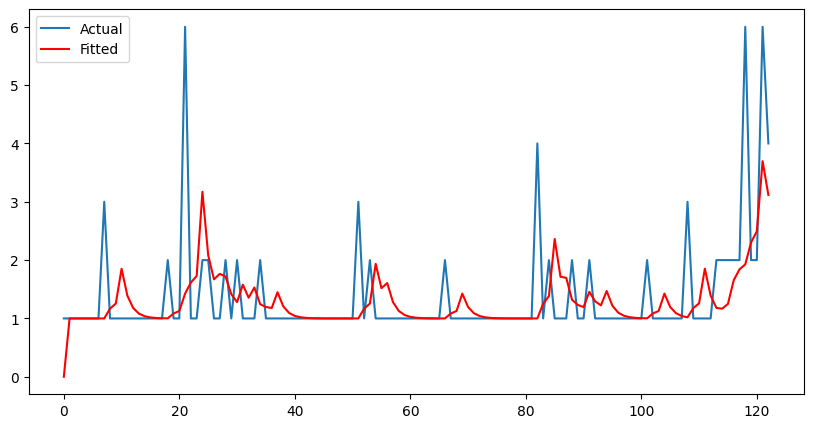

In [120]:
import matplotlib.pyplot as plt

daily_totals["fitted"] = best_fit.fittedvalues
plt.figure(figsize=(10,5))
plt.plot(daily_totals["count"], label="Actual")
plt.plot(daily_totals["fitted"], label="Fitted", color="red")
plt.legend()
plt.show()


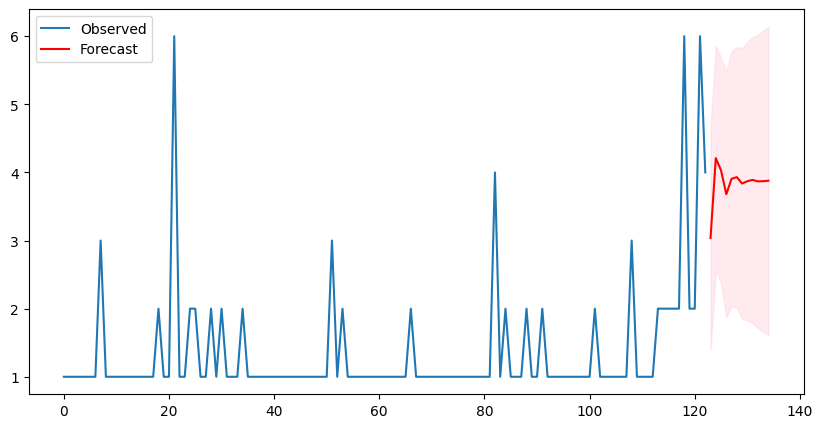

In [121]:
forecast = best_fit.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

plt.figure(figsize=(10,5))
plt.plot(daily_totals["count"], label="Observed")
plt.plot(forecast_mean, label="Forecast", color="red")
plt.fill_between(forecast_ci.index,
                 forecast_ci.iloc[:,0],
                 forecast_ci.iloc[:,1],
                 color="pink", alpha=0.3)
plt.legend()
plt.show()


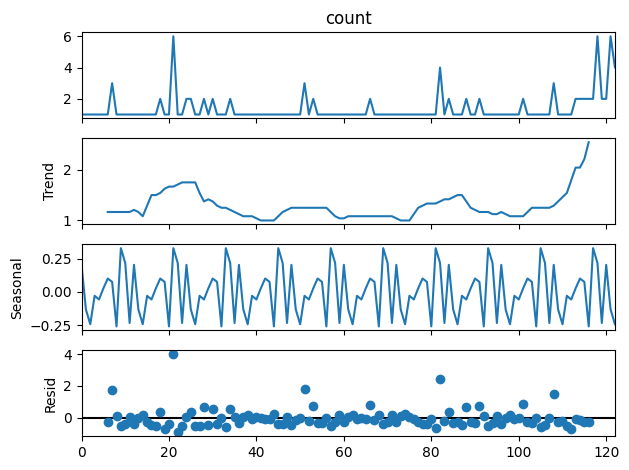

In [122]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(daily_totals["count"], period=12, model="additive")
decomposition.plot()
plt.show()


# SARIMA

In [126]:
import warnings
import itertools
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Suppress warnings for convergence issues
warnings.filterwarnings("ignore")

def sarima_grid_search(series, p_range, d_range, q_range, 
                       P_range, D_range, Q_range, s, verbose=True):
    """
    Grid search for best SARIMA model.
    series : pandas Series (time series data)
    (p,d,q): non-seasonal ARIMA orders
    (P,D,Q): seasonal orders
    s      : seasonality period (e.g., 12 for monthly, 7 for weekly, etc.)
    """
    best_aic = float("inf")
    best_order = None
    best_seasonal_order = None
    best_model = None
    
    # Create parameter combinations
    pdq = list(itertools.product(p_range, d_range, q_range))
    seasonal_pdq = list(itertools.product(P_range, D_range, Q_range, [s]))
    
    for order in pdq:
        for seasonal_order in seasonal_pdq:
            try:
                model = SARIMAX(series,
                                order=order,
                                seasonal_order=seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)
                results = model.fit(disp=False)
                
                if results.aic < best_aic:
                    best_aic = results.aic
                    best_order = order
                    best_seasonal_order = seasonal_order
                    best_model = results
                    
                if verbose:
                    print(f"SARIMA{order}x{seasonal_order} - AIC:{results.aic}")
                    
            except Exception as e:
                if verbose:
                    print(f"SARIMA{order}x{seasonal_order} - failed: {e}")
                continue
    
    print("\n✅ Best SARIMA order:", best_order, "seasonal:", best_seasonal_order, "AIC:", best_aic)
    return best_model, best_order, best_seasonal_order


In [125]:
# Assuming df['count'] is your series
best_model, best_order, best_seasonal = sarima_grid_search(
    daily_totals["count"],
    p_range=range(0,3), d_range=range(0,2), q_range=range(0,3),
    P_range=range(0,3), D_range=range(0,2), Q_range=range(0,3),
    s=12
)

print(best_model.summary())


SARIMA(0, 0, 0)x(0, 0, 0, 12) - AIC:472.54203389529584
SARIMA(0, 0, 0)x(0, 0, 1, 12) - AIC:395.0424212662413
SARIMA(0, 0, 0)x(0, 0, 2, 12) - AIC:339.4295460455891
SARIMA(0, 0, 0)x(0, 1, 0, 12) - AIC:362.05146514475535
SARIMA(0, 0, 0)x(0, 1, 1, 12) - AIC:285.2278843246179
SARIMA(0, 0, 0)x(0, 1, 2, 12) - AIC:258.4863703294985
SARIMA(0, 0, 0)x(1, 0, 0, 12) - AIC:362.4235147869855
SARIMA(0, 0, 0)x(1, 0, 1, 12) - AIC:333.35333016124514
SARIMA(0, 0, 0)x(1, 0, 2, 12) - AIC:306.05643207654845
SARIMA(0, 0, 0)x(1, 1, 0, 12) - AIC:299.13141519264843
SARIMA(0, 0, 0)x(1, 1, 1, 12) - AIC:295.26373484150844
SARIMA(0, 0, 0)x(1, 1, 2, 12) - AIC:259.9731606084164
SARIMA(0, 0, 0)x(2, 0, 0, 12) - AIC:300.7018150755718
SARIMA(0, 0, 0)x(2, 0, 1, 12) - AIC:300.09657026800363
SARIMA(0, 0, 0)x(2, 0, 2, 12) - AIC:296.31296322550327
SARIMA(0, 0, 0)x(2, 1, 0, 12) - AIC:252.9480267265099
SARIMA(0, 0, 0)x(2, 1, 1, 12) - AIC:252.901570177523
SARIMA(0, 0, 0)x(2, 1, 2, 12) - AIC:252.73861992352542
SARIMA(0, 0, 1)x(0, 

In [127]:
import warnings
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Suppress warnings
warnings.filterwarnings("ignore")

def sarima_grid_search(series, p_range, d_range, q_range, 
                       P_range, D_range, Q_range, s, forecast_steps=12, verbose=True):
    best_aic = float("inf")
    best_order = None
    best_seasonal_order = None
    best_model = None
    
    # Generate parameter grid
    pdq = list(itertools.product(p_range, d_range, q_range))
    seasonal_pdq = list(itertools.product(P_range, D_range, Q_range, [s]))
    
    for order in pdq:
        for seasonal_order in seasonal_pdq:
            try:
                model = SARIMAX(series,
                                order=order,
                                seasonal_order=seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)
                results = model.fit(disp=False)
                
                if results.aic < best_aic:
                    best_aic = results.aic
                    best_order = order
                    best_seasonal_order = seasonal_order
                    best_model = results
                    
                if verbose:
                    print(f"SARIMA{order}x{seasonal_order} - AIC:{results.aic}")
                    
            except Exception as e:
                if verbose:
                    print(f"SARIMA{order}x{seasonal_order} failed: {e}")
                continue
    
    print("\n✅ Best SARIMA order:", best_order, "seasonal:", best_seasonal_order, "AIC:", best_aic)
    
    # === Diagnostics ===
    best_model.plot_diagnostics(figsize=(12, 6))
    plt.show()
    
    # === Forecasting ===
    pred = best_model.get_prediction(start=0, end=len(series)+forecast_steps, dynamic=False)
    pred_ci = pred.conf_int()
    
    plt.figure(figsize=(12, 6))
    plt.plot(series.index, series, label="Observed")
    plt.plot(pred.predicted_mean.index, pred.predicted_mean, label="Forecast", color="red")
    
    # Confidence intervals
    plt.fill_between(pred_ci.index,
                     pred_ci.iloc[:, 0],
                     pred_ci.iloc[:, 1], color="pink", alpha=0.3)
    
    plt.title(f"SARIMA{best_order}x{best_seasonal_order} Forecast")
    plt.legend()
    plt.show()
    
    return best_model, best_order, best_seasonal_order


SARIMA(0, 0, 0)x(0, 0, 0, 12) - AIC:472.54203389529584
SARIMA(0, 0, 0)x(0, 0, 1, 12) - AIC:395.0424212662413
SARIMA(0, 0, 0)x(0, 0, 2, 12) - AIC:339.4295460455891
SARIMA(0, 0, 0)x(0, 1, 0, 12) - AIC:362.05146514475535
SARIMA(0, 0, 0)x(0, 1, 1, 12) - AIC:285.2278843246179
SARIMA(0, 0, 0)x(0, 1, 2, 12) - AIC:258.4863703294985
SARIMA(0, 0, 0)x(1, 0, 0, 12) - AIC:362.4235147869855
SARIMA(0, 0, 0)x(1, 0, 1, 12) - AIC:333.35333016124514
SARIMA(0, 0, 0)x(1, 0, 2, 12) - AIC:306.05643207654845
SARIMA(0, 0, 0)x(1, 1, 0, 12) - AIC:299.13141519264843
SARIMA(0, 0, 0)x(1, 1, 1, 12) - AIC:295.26373484150844
SARIMA(0, 0, 0)x(1, 1, 2, 12) - AIC:259.9731606084164
SARIMA(0, 0, 0)x(2, 0, 0, 12) - AIC:300.7018150755718
SARIMA(0, 0, 0)x(2, 0, 1, 12) - AIC:300.09657026800363
SARIMA(0, 0, 0)x(2, 0, 2, 12) - AIC:296.31296322550327
SARIMA(0, 0, 0)x(2, 1, 0, 12) - AIC:252.9480267265099
SARIMA(0, 0, 0)x(2, 1, 1, 12) - AIC:252.901570177523
SARIMA(0, 0, 0)x(2, 1, 2, 12) - AIC:252.73861992352542
SARIMA(0, 0, 1)x(0, 

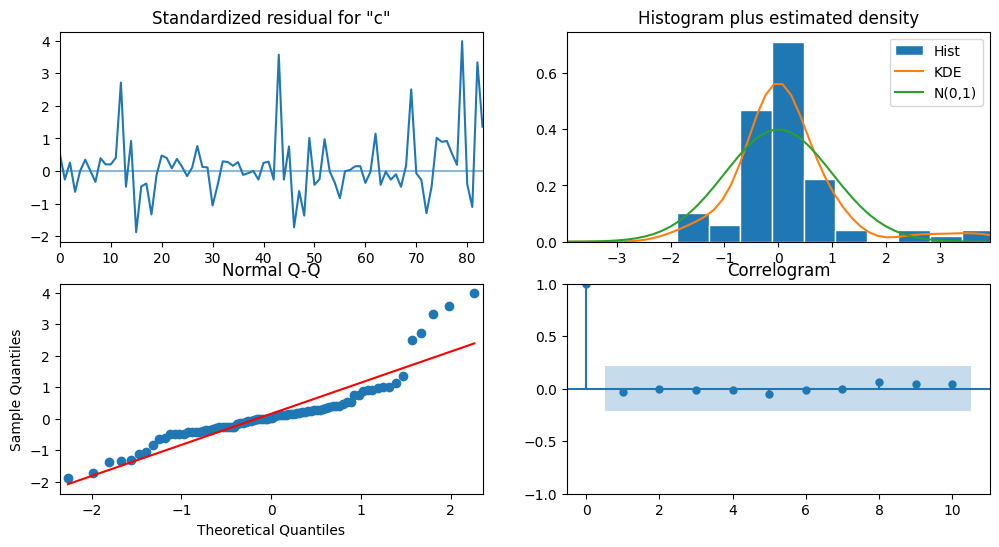

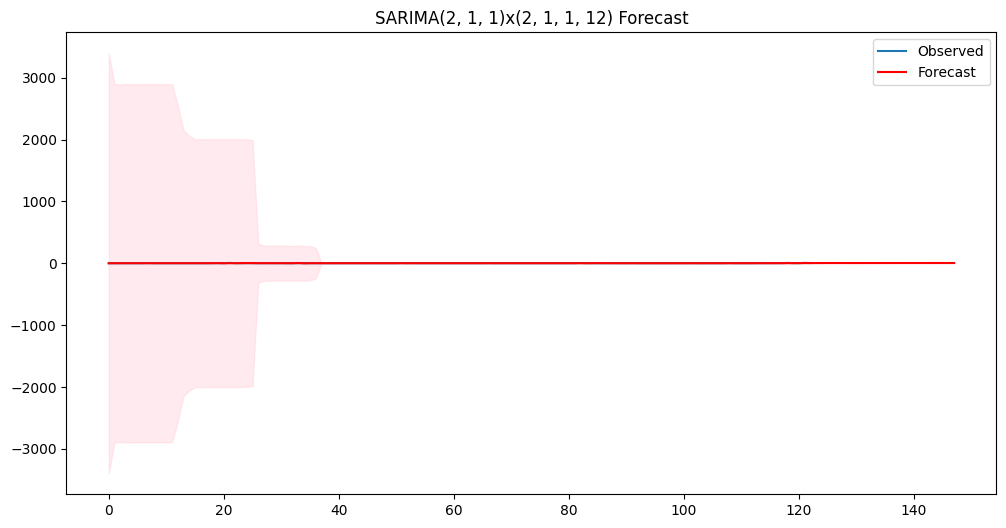

In [128]:
# Run SARIMA grid search
best_model, best_order, best_seasonal = sarima_grid_search(
    daily_totals["count"],
    p_range=range(0,3), d_range=range(0,2), q_range=range(0,3),
    P_range=range(0,3), D_range=range(0,2), Q_range=range(0,3),
    s=12, forecast_steps=24
)
